# Walkthrough: forecasting next-quarter road deaths by state

This notebook runs the full pipeline from the raw FRSC sheet to the backtest results. The logic lives in `src/`; this is the guided tour.

In [1]:
import sys, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from IPython.display import Image, Markdown, display

## 1. Clean the raw sheet

The sheet has 15 quarterly blocks and 4 yearly-total blocks. The script proves the yearly blocks are sums of quarters, drops them, recovers one missing value and flags one inconsistency.

In [2]:
subprocess.run([sys.executable, str(ROOT / 'src' / 'prepare_data.py')], check=True, capture_output=True)
display(Markdown((ROOT / 'data' / 'data_quality_report.md').read_text()))
panel = pd.read_csv(ROOT / 'data' / 'crashes_state_quarter.csv')
panel.head()

# Data quality report

Source: Federal Road Safety Corps (FRSC) state crash returns, 2020Q4 to 2024Q2.
Rows written: 555 (37 states including FCT x 15 quarters).

## Issues found

- Blocks 16 to 19 of the sheet are yearly totals (2021, 2022, 2023, H1 2024). Each matches the sum of its quarters exactly, so they were dropped.
- Borno 2021Q3: blank killed, total_casualties in the source.
  - Recovered Borno 2021Q3 killed = 18 from the national total minus all other states.
- Benue 2021Q3: total casualties 113 does not equal injured + killed (162). Casualties are recomputed as injured + killed; the model does not use this column.


,state,fatal_crashes,serious_crashes,minor_crashes,total_crashes,injured,killed,total_casualties,people_involved,quarter
0,Abia,10,19,1,30,146,31,177,279,2020Q4
1,Abia,16,23,5,44,119,35,154,289,2021Q1
2,Abia,10,11,0,21,69,19,88,177,2021Q2
3,Abia,7,10,3,20,62,11,73,140,2021Q3
4,Abia,3,12,6,21,57,3,60,177,2021Q4


## 2. Build leakage-safe features

Each row is a state and a target quarter T. Every feature comes from quarter T-1 or earlier.

In [3]:
from features import build_feature_table, FEATURES
feats = build_feature_table(panel)
print(len(feats), 'rows, targets', feats.target_quarter.min(), 'to', feats.target_quarter.max())
feats[['state','target_quarter','y','killed_lag1','killed_lag4','killed_mean4','fatal_crashes_lag1']].head()

407 rows, targets 2021Q4 to 2024Q2


,state,target_quarter,y,killed_lag1,killed_lag4,killed_mean4,fatal_crashes_lag1
0,Abia,2021Q4,3,11,31,24.0,7
1,Adamawa,2021Q4,25,26,36,26.0,14
2,Akwa Ibom,2021Q4,10,1,7,7.5,1
3,Anambra,2021Q4,45,17,20,16.0,12
4,Bauchi,2021Q4,156,79,90,82.5,39


## 3. Rolling-origin backtest

For each of the last six quarters, train on earlier quarters only and forecast all 37 states.

In [4]:
import os
os.chdir(ROOT / 'src')
from backtest import run
preds, metrics, fold = run()
metrics

Training rows available: 407; test quarters: ['2023Q1', '2023Q2', '2023Q3', '2023Q4', '2024Q1', '2024Q2']
                                           MAE   RMSE  bias MAE vs naive
model                                                                   
Mean of last 4 quarters                  12.47  17.73  2.91       -20.6%
XGBoost (Poisson)                        12.68  17.20  4.08       -19.2%
Poisson GLM                              13.11  17.38  6.95       -16.5%
Ridge (log)                              13.35  17.71  5.77       -15.0%
Naive (last quarter)                     15.70  20.46  1.36         0.0%
Seasonal naive (same quarter last year)  17.15  24.45  6.53         9.2%

model           Mean of last 4 quarters  Naive (last quarter)  Poisson GLM  Ridge (log)  Seasonal naive (same quarter last year)  XGBoost (Poisson)
target_quarter                                                                                                                                     
2023Q1       

,MAE,RMSE,bias,MAE vs naive
model,,,,
Mean of last 4 quarters,12.47,17.73,2.91,-20.6%
XGBoost (Poisson),12.68,17.20,4.08,-19.2%
Poisson GLM,13.11,17.38,6.95,-16.5%
Ridge (log),13.35,17.71,5.77,-15.0%
Naive (last quarter),15.70,20.46,1.36,0.0%
Seasonal naive (same quarter last year),17.15,24.45,6.53,9.2%


In [5]:
display(Markdown((ROOT / 'results' / 'comparison.md').read_text()))
fold

Lowest MAE overall: **Mean of last 4 quarters**. Best learned model: **XGBoost (Poisson)**.

- **Mean of last 4 quarters** vs **Naive (last quarter)**: mean change in absolute error -3.23 deaths per state-quarter (95% state-bootstrap interval -4.33 to -2.18); Mean of last 4 quarters was closer on 61% of 222 state-quarters.
- **XGBoost (Poisson)** vs **Naive (last quarter)**: mean change in absolute error -3.01 deaths per state-quarter (95% state-bootstrap interval -4.12 to -1.91); XGBoost (Poisson) was closer on 62% of 222 state-quarters.
- **XGBoost (Poisson)** vs **Mean of last 4 quarters**: mean change in absolute error +0.22 deaths per state-quarter (95% state-bootstrap interval -0.53 to +0.95); XGBoost (Poisson) was closer on 43% of 222 state-quarters.


model,Mean of last 4 quarters,Naive (last quarter),Poisson GLM,Ridge (log),Seasonal naive (same quarter last year),XGBoost (Poisson)
target_quarter,,,,,,
2023Q1,12.61,15.49,15.22,12.43,22.24,13.31
2023Q2,12.48,17.89,11.51,12.95,16.19,10.62
2023Q3,17.95,17.59,17.18,15.67,20.54,16.95
2023Q4,9.77,16.24,10.50,13.22,12.78,11.30
2024Q1,13.47,12.00,14.10,14.59,19.03,13.48
2024Q2,8.52,14.97,10.12,11.23,12.11,10.44


## 4. What happens with leaky validation

In [6]:
import leakage_demo
leakage_demo.main()

                                  validation   MAE vs honest
         Honest: train on past quarters only 12.68      0.0%
       Leak 1: also train on future quarters 12.53     -1.3%
Leak 2: past only, state level from all rows 12.59     -0.7%
                        Leaks 1 + 2 together 12.42     -2.1%


## 5. Charts

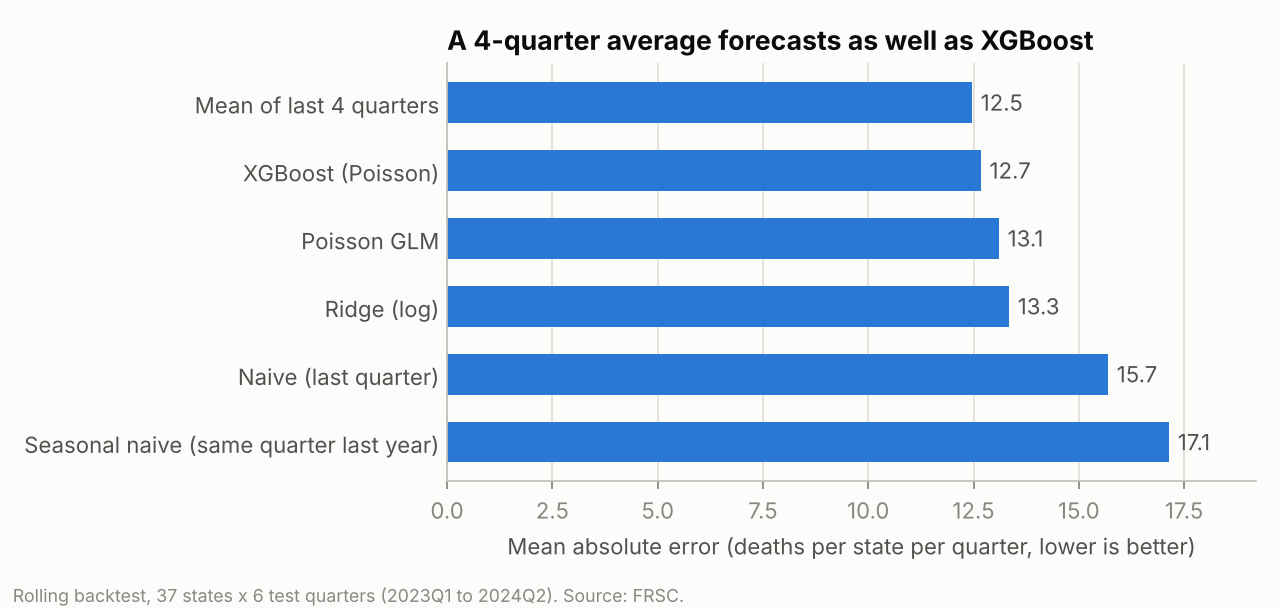

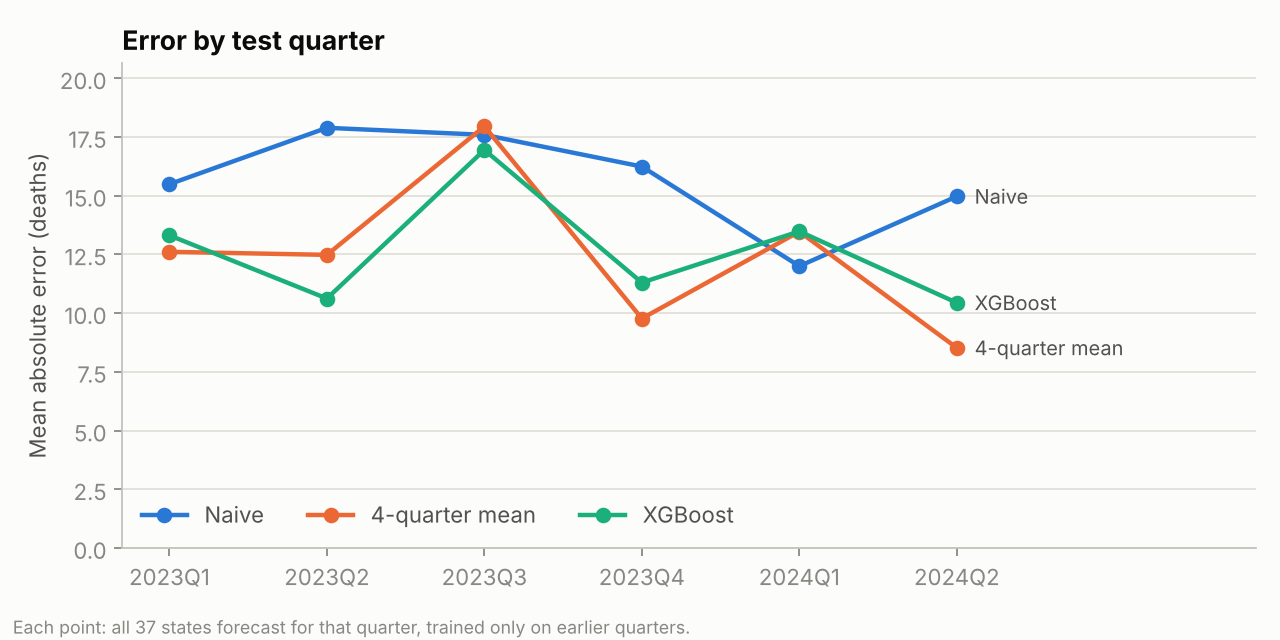

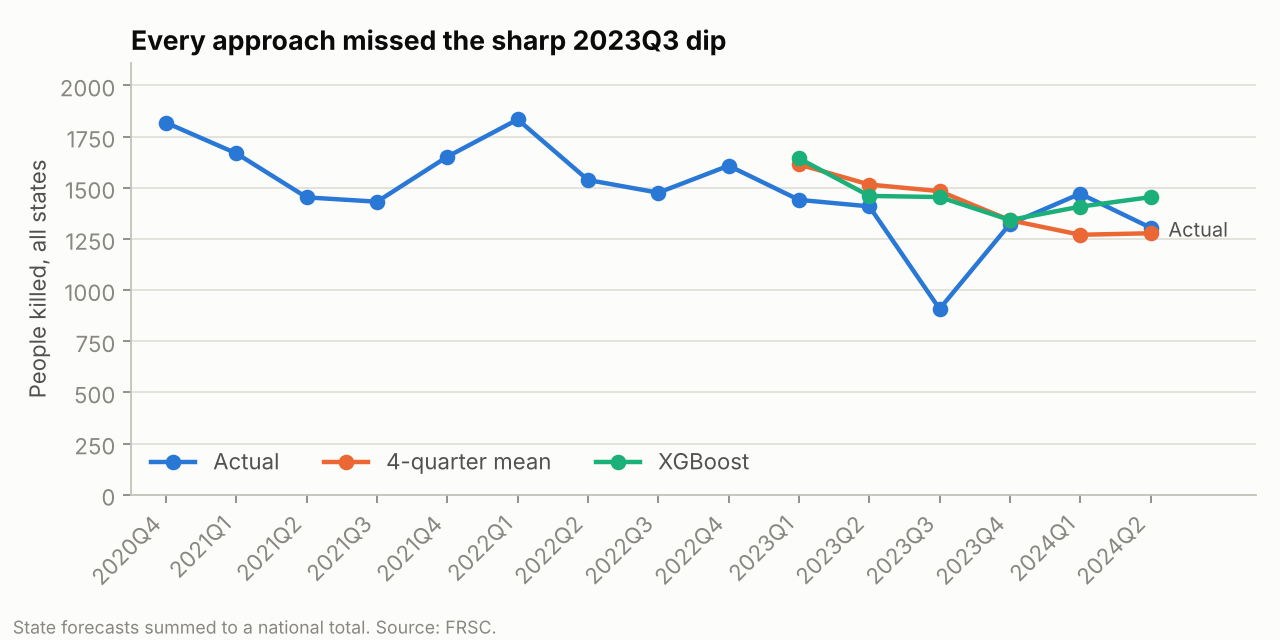

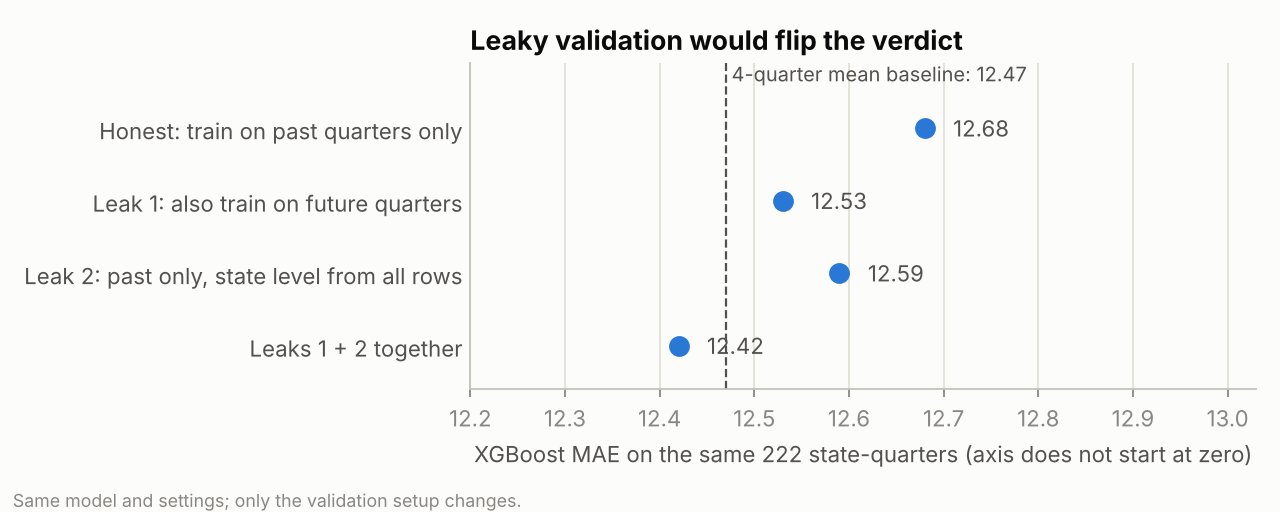

In [7]:
import make_charts
(ROOT / 'figures').mkdir(exist_ok=True)
for fn in (make_charts.model_mae, make_charts.mae_by_quarter, make_charts.national_forecast, make_charts.leakage):
    fn()
for name in ('model_mae', 'mae_by_quarter', 'national_forecast', 'leakage_demo'):
    display(Image(str(ROOT / 'figures' / f'{name}.png')))
os.chdir(ROOT)

## Takeaway

A 4-quarter average is as accurate as XGBoost here, and both beat the naive baseline by about 20%. Honest, time-ordered validation is what makes that conclusion trustworthy.